# Evolution log — Cicero → `epione.tl`

One `## Iteration N — <title>` block per iteration of the port, each with the narrative and a
subplot of the trajectory so far (wall-clock top, parity bottom), as required by
omicverse-rebuildr `NOTEBOOKS.md`. Numbers come from `../ITERATION_LOG.md` (benchmark:
`make_cicero_cds` + `run_cicero` on F1, 1 warm-up + 3 runs; parity = gate 10, Pearson of
coaccess vs R, threshold 0.9999; gate 9's max abs error is shown as a second marker).

## Setup

In [1]:
import re, yaml
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
LOG = Path("..") / "ITERATION_LOG.md"
blocks = re.findall(r"##\s+(iter\s+\d+|Baseline)\s*—[^\n]*\n+```yaml\n(.*?)\n```", LOG.read_text(), re.S)
it = {b["iter"]: b for b in (yaml.safe_load(t) for _, t in blocks)}
MAXERR = {0: 8.0e-16, 1: 8.0e-16, 2: 8.0e-16, 3: 8.0e-16, 4: 8.0e-16, 5: 8.9e-16, 6: 8.0e-16, 7: 8.0e-16}   # gate 9 on F1 (bench JSONs)
def upto(n):
    xs = [i for i in sorted(it) if i <= n]
    fig, (a, b) = plt.subplots(2, 1, figsize=(6, 4.2), sharex=True)
    acc = [i for i in xs if it[i]["status"] in ("baseline", "ACCEPT")]
    a.errorbar(acc, [it[i]["wall_clock_mean_s"] for i in acc], yerr=[it[i]["wall_clock_stddev_s"] for i in acc], marker="o", color="#0078d4")
    rej = [i for i in xs if i not in acc]
    a.scatter(rej, [it[i]["wall_clock_mean_s"] for i in rej], marker="x", color="grey", zorder=3, label="rejected")
    a.set_yscale("log"); a.set_ylabel("wall-clock F1 (s)"); a.grid(alpha=.3)
    if rej: a.legend(frameon=False, fontsize=8)
    b.plot(acc, [1 - it[i]["parity_metric"] for i in acc], marker="o", color="#107c10", label="1 − Pearson (gate 10)")
    b.plot(xs, [MAXERR[i] for i in xs], marker="s", color="#8a8886", ls=":", label="max abs err (gate 9)")
    b.axhline(1e-4, color="red", ls="--", lw=1, label="gate 10 threshold (1 − 0.9999)")
    b.axhline(1e-8, color="orange", ls="--", lw=1, label="gate 9 threshold")
    b.set_yscale("symlog", linthresh=1e-17); b.set_ylabel("distance to R"); b.set_xlabel("iteration"); b.grid(alpha=.3)
    b.legend(fontsize=7, frameon=False, loc="upper left"); b.set_xticks(range(0, max(it) + 1))
    a.scatter([n], [it[n]["wall_clock_mean_s"]], s=150, facecolors="none", edgecolors="crimson")
    plt.tight_layout(); plt.show()

## Iteration 0 — Baseline translation

Every exported R function on the pipeline path was translated in dependency order: `glasso.f` (connect / row / lasinv1 / setup / lasso / fatmul / inv) to numba keeping the Fortran accumulation order; `make_cicero_cds` with R's `sample()` stream reproduced by `RRandom`; `get_genomic_range`, `get_rho_mat`, `find_distance_parameter`, `cov2cor`, `reconcile` and data.table's key order mirrored; R's long-double `mean()` and `cov()` emulated with numpy `longdouble`. The first full run already cleared every deterministic gate on F1 (bins, windows, bit-identical mean distance parameter, coaccess max abs error 8e-16 in R's row order). The one finding of this pass came from `annotate_cds_by_site`: `findOverlaps` reports a query's hits in NCList order (feature start, then end), not subject order, which decides ties between equally overlapping promoters; fixed before the first commit.

**Status**: baseline. **ITERATION_LOG cross-ref**: [iter 0](../ITERATION_LOG.md)

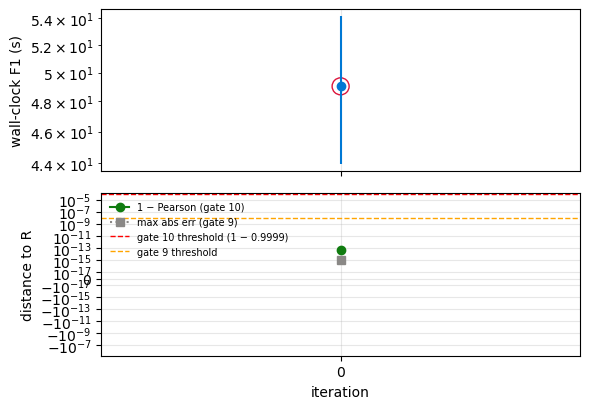

In [2]:
upto(0)

## Iteration 1 — Covariance: upper triangle, row-wise long-double sums (exact)

R's `cov_na_1` forms only `j <= i`. The covariance was rewritten to build the upper triangle and add one row of double products at a time into a long-double accumulator — the same additions in the same order, verified bit for bit against a naive loop. On F1 (25 bins) covariance is negligible, so the gain only shows on F2-sized windows (3.4 s → 1.3 s per 200-site window).

**Status**: ACCEPT. **ITERATION_LOG cross-ref**: [iter 1](../ITERATION_LOG.md)

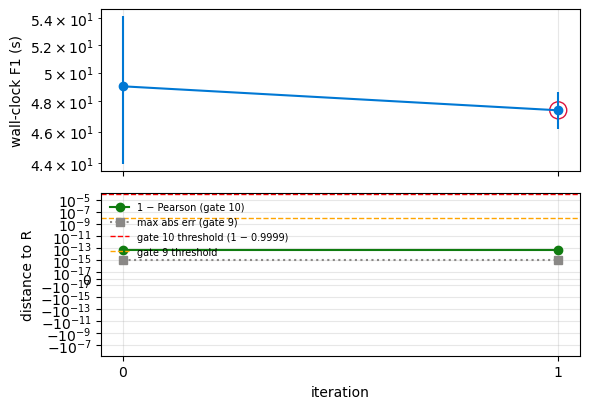

In [3]:
upto(1)

## Iteration 2 — Distance parameter: replay sampling, bisect each window once (exact)

`find_distance_parameter` returns a non-number only for "No long edges", which depends on peak positions alone, so R's sampling loop can be replayed with cheap checks first; then each distinct window (windows are drawn with replacement) is bisected once. Exact by construction; small gain on F1 (≈ 1.04×, within noise).

**Status**: ACCEPT. **ITERATION_LOG cross-ref**: [iter 2](../ITERATION_LOG.md)

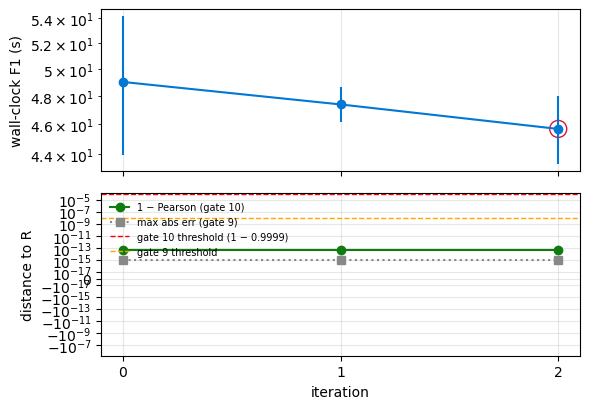

In [4]:
upto(2)

## Iteration 3 — Threads over windows (exact)

Windows are independent (R uses `mclapply(mc.cores = 1)`). Bisections and window models run in a thread pool; the numba solver is `nogil` and numpy long-double ufuncs release the GIL, results are collected in window order. 10× on F1 with 8 threads, output identical for any `n_jobs`.

**Status**: ACCEPT. **ITERATION_LOG cross-ref**: [iter 3](../ITERATION_LOG.md)

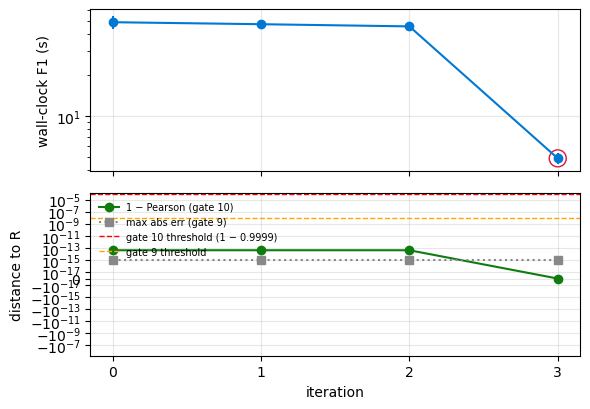

In [5]:
upto(3)

## Iteration 4 — Equivalence: remaining exported utilities and R's locale collation

Not a speed step. The six remaining exported utilities were ported after an addendum pre-registration (gates 19–24). Gate 21 failed on row order: R sorts factor levels and `dcast` output with the session's collation (en_US.UTF-8: punctuation < digits < letters, case-insensitive, lowercase first), not by bytes. `_r_sorted()` reproduces R's `sort()`; data.table output stays in byte order. All addendum gates then passed exactly.

**Status**: ACCEPT. **ITERATION_LOG cross-ref**: [iter 4](../ITERATION_LOG.md)

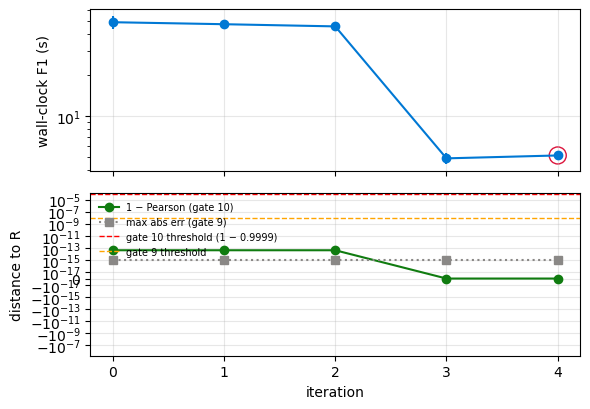

In [6]:
upto(4)

## Iteration 5 — BLAS covariance (bounded) — rejected

Candidate (B): a double-precision BLAS covariance. Every gate still passed on F2 (coaccess error 6.9e-15, mean distance parameter off by 5.5e-16 relative) and `run_cicero` went from 32.6 s to 8.9 s with 8 threads. Rejected: the brief admits only provably equivalent rewrites, and this one is bounded, not exact.

**Status**: REJECT_INADMISSIBLE. **ITERATION_LOG cross-ref**: [iter 5](../ITERATION_LOG.md)

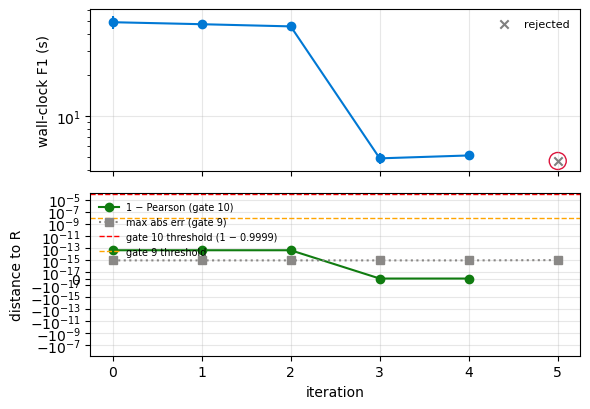

In [7]:
upto(5)

## Iteration 6 — Compiled x87 long-double covariance (exact)

R's `LDOUBLE` is the x87 80-bit format on x86-64. A numba intrinsic emits LLVM `x86_fp80` code — `fpext`, one x87 `fadd`, `fptrunc` — exactly what GCC compiles `sum += prod` to; the running sum is held exactly as hi + lo doubles. Bit-identical to the numpy long-double path (tests) and to R on F2 (mean distance parameter equal, coaccess error 4.4e-16); per-window covariance 6× faster and F2 `run_cicero` 32.6 s → 11.6 s with 8 threads. F1 is glasso-bound, hence flat here.

**Status**: ACCEPT. **ITERATION_LOG cross-ref**: [iter 6](../ITERATION_LOG.md)

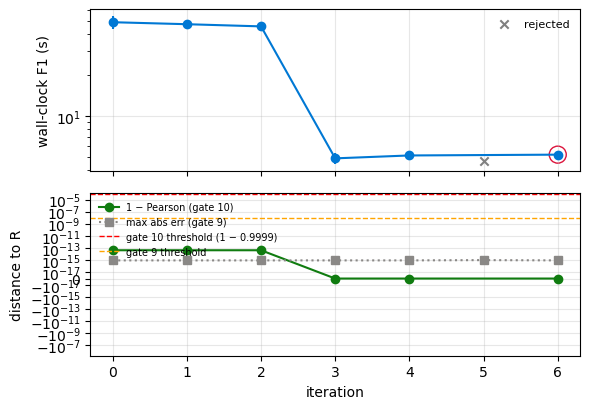

In [8]:
upto(6)

## Iteration 7 — Equivalence: Louvain on R's random stream, R's round()

The last output that differed from R was the CCAN membership: R's `cluster_louvain` is igraph's multilevel algorithm drawing from R's `unif_rand()` through a 30-bit bridge, while python-igraph has its own generator. Ported: the algorithm (`louvain.c`, C core 0.10), igraph's bounded integers and shuffle, the undirected edge store and `igraph_incident` order, `igraph_qsort` (its order of equal keys decides the order of floating-point sums) and the graph Cicero builds, zero-weight self loops included. The cutoff search then still diverged at its fifth step: R 4.x `round(x, 3)` is not the correctly rounded decimal (`round(0.10549999999999999656, 3)` is 0.106), so `fround.c` was ported too. Now `generate_ccans` returns R's exact table for five seeds on F1 and F2; F1's gate 16 goes from 0.935 (fail) to 1.

**Status**: ACCEPT. **ITERATION_LOG cross-ref**: [iter 7](../ITERATION_LOG.md)

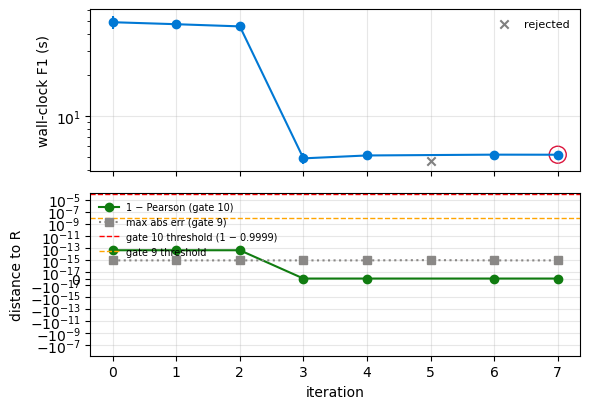

In [9]:
upto(7)

## Aggregate evolution figure

[plot] wrote /scratch/users/steorra/analysis/26_dynode-project/cicero_port/epione/tests/parity/cicero/examples/evolution.png


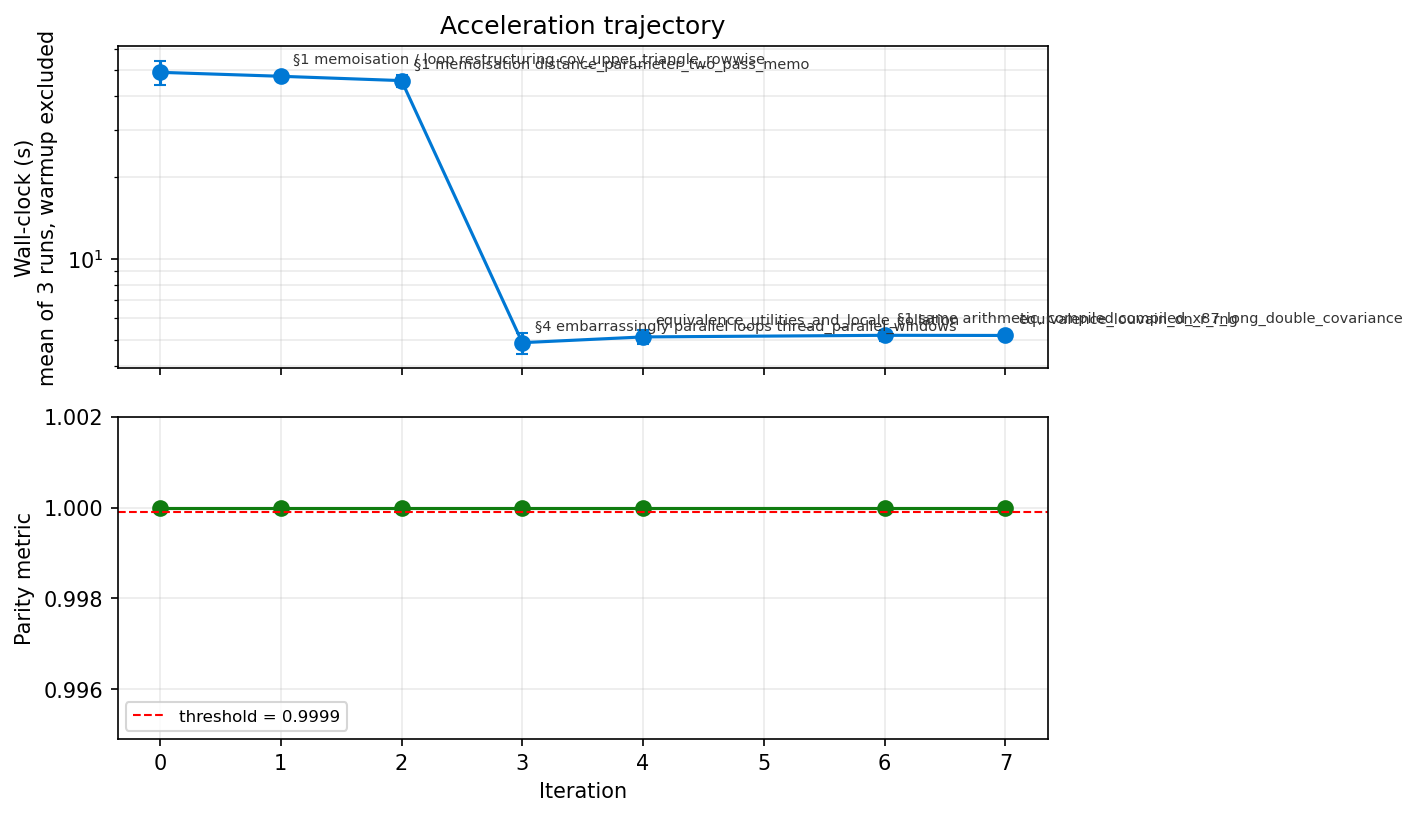

In [10]:
import os, sys, subprocess
kit = os.environ.get("REBUILDR_KIT")
if kit:
    subprocess.run([sys.executable, "-m", "engine.plot_evolution", "--port-dir", str(Path("..").resolve()),
                    "--output", str(Path("evolution.png").resolve()), "--threshold", "0.9999"], cwd=kit, check=True)
else:
    upto(max(it)); plt.gcf().savefig("evolution.png", dpi=150)
from IPython.display import Image
Image("evolution.png")